<p style="text-align:center"><img src="../../../Images/Banner/01_banner_vector.png" alt="Working with Vector Data" width="100%"></p>


# Coordinate Reference Systems (CRS)

This notebook provides a practical introduction to working with Coordinate Reference Systems (CRS) and map projections using the GeoLattice library. You'll learn CRS fundamentals, types of projections, and how to inspect, assign, and transform projections for vector data in real-world geospatial workflows. By the end, you'll be able to use GeoLattice tools to manage and reproject layers, ensuring your spatial analysis is accurate and consistent.


## Overview

This tutorial covers coordinate reference systems (CRS) for vector data: what a geographic and a projected CRS are, how common projections are defined, and how to assign and reproject layers with `geolattice.vector.vector_CRS`.

Coordinate Reference Systems (CRS) are used in cartography, geography, and GIS (Geographic Information Systems) to define the positions of points, lines, and areas on the Earth's surface. A CRS provides a framework for translating geographic locations, which are expressed as latitude and longitude or other coordinate values, into a specific location on a map or a two-dimensional plane.

There are two main types of Coordinate Reference Systems:

1. Geographic Coordinate Systems (GCS): Geographic Coordinate Systems use latitude and longitude to define locations on the Earth's surface. Latitude measures the north-south position, while longitude measures the east-west position. The coordinates are expressed in degrees, minutes, and seconds or decimal degrees. Common GCS examples include WGS 84 (World Geodetic System 1984) and NAD83 (North American Datum 1983).

2. Projected Coordinate Systems (PCS): Projected Coordinate Systems use Cartesian coordinates (X, Y) to represent locations on a flat, two-dimensional map. The projection converts the three-dimensional geographic coordinates (latitude, longitude, and often elevation) into these two-dimensional coordinates. Different map projections, such as Mercator, Robinson, or UTM (Universal Transverse Mercator), create projected coordinate systems.

Source: [Esri, Coordinate systems and projections](https://pro.arcgis.com/en/pro-app/latest/help/mapping/properties/coordinate-systems-and-projections.htm)

<img src="../../../Images/CRS/Pic1.png" alt="A geographic coordinate system, with latitude and longitude on the globe" width="320">

The equidistant lines that run east and west each have a constant latitude value called **parallels**. The **equator** is the largest circle and divides the earth in half. It is equal in distance from each of the poles, and the value of this latitude line is zero. Locations north of the equator have positive latitudes that range from **0 to +90 degrees**, while locations south of the equator have negative latitudes that range from **0 to -90 degrees**.

<img src="../../../Images/CRS/Pic2.png" alt="Parallels of latitude" width="280">

The lines that run through north and south each have a constant longitude value and form circles of the same size around the earth known as **meridians**. The **prime meridian** is the line of longitude that defines the origin (zero degrees) for longitude coordinates. One of the most commonly used prime meridian locations is the line that passes through Greenwich, England. Locations east of the prime meridian up to its antipodal meridian (the continuation of the prime meridian on the other side of the globe) have positive longitudes ranging from **0 to +180 degrees**. Locations west of the prime meridian have negative longitudes ranging from **0 to -180 degrees**.

<img src="../../../Images/CRS/Pic3.png" alt="Meridians of longitude" width="280">

The latitude and longitude lines cover the globe to form a grid known as a **graticule**. The point of origin of the graticule is (0, 0), where the equator and the prime meridian intersect. The equator is the only place on the graticule where the linear distance corresponding to one degree of latitude is approximately equal to the distance corresponding to one degree of longitude. Because the longitude lines converge at the poles, the distance between two meridians is different at every parallel.

To maintain accuracy in GIS and cartographic applications, it is essential to use the appropriate coordinate reference system and datum for the specific region or project. Choosing the wrong CRS can lead to distortions and inaccuracies when transforming between geographic locations and map coordinates.

CRS is a fundamental aspect of spatial data management, as they allow for the integration of different data sources, analysis, and visualization of geographic information consistently and meaningfully. Understanding CRS is crucial for cartographers, GIS analysts, and anyone working with geographic data to ensure accurate spatial representation and analysis.

The notebook is organized in three parts:

1. **CRS concepts**: map projections, WGS 84, UTM, PROJ strings, and Albers Equal Area Conic.
2. **Bangladesh districts**: assign WGS 84 to a shapefile with no `.prj`, then project to Bangladesh Transverse Mercator.
3. **New York counties**: reproject a WGS 84 county layer to North America Albers (ESRI:102008).

Sample shapefiles live in `Data/00_shared/vector_data/Bangladesh/Shapefiles` and `Data/00_shared/vector_data/USA`. Written outputs land in `Data/00_shared/vector_data/output_folder` under `bangladesh` and `ny_county`.


## Setup

The next cell finds the repository root and puts it on the import path. Part 2 reads `Data/00_shared/vector_data/Bangladesh/Shapefiles`. Part 3 reads `Data/00_shared/vector_data/USA`. Written shapefiles go in `Data/00_shared/vector_data/output_folder`, under `bangladesh` and `ny_county`, the same output folder used by the vector writing tutorial.

Shared CRS definitions live in `geolattice.crs` (the PROJ database through pyproj, the same catalog published at [SpatialReference.org](https://spatialreference.org/)). Vector-specific work uses `geolattice.vector.vector_CRS`:

* `define_crs` / `validate_crs`: build and check a CRS for a layer
* `reproject_vector`: transform geometries (or a GeoDataFrame) to a target CRS
* `is_geographic` / `crs_equal`: inspect equivalence and kind

`read_vector_data` and `write_shapefile` open and write each layer. `plot_layer` draws one layer, and `plot_pair` draws the geographic and projected maps side by side.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

import sys  # tweak the Python import path so local geolattice is findable
from pathlib import Path  # filesystem paths for data and output folders

import pandas as pd  # tabular display helpers (column width, etc.)
from IPython.display import display  # pretty-print DataFrames in the notebook
from osgeo import gdal  # GDAL bindings (version check and quiet error handler)


In [2]:

# ===================================================================
# Setup and helpers for CRS definition, reprojection, and maps.
# ===================================================================
# Locate the GeoLattice repo root, import CRS/vector helpers, create output folders,
# quiet GDAL warnings, and define show_crs() for readable CRS summaries.

# Resolve the current working directory as a starting point for the root search.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "vector_data").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/vector_data from the working directory.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from geolattice.crs import CRS  # GeoLattice CRS wrapper used by show_crs()
from geolattice.vector import read_vector_data, write_shapefile  # open/write vector layers
from geolattice.vector.vector_CRS import (  # CRS helpers used throughout this notebook
    crs_equal,  # compare two CRS definitions for equivalence
    define_crs,  # build a CRS from EPSG, PROJ, WKT, etc.
    is_geographic,  # True when the CRS uses lon/lat degrees
    reproject_vector,  # transform geometries into a target CRS
    validate_crs,  # normalize/validate a CRS input
)  # close this call
from geolattice.viz import apply_map_style, plot_layer, plot_pair  # map styling and plots

# Bangladesh district shapefiles live under Data/00_shared/vector_data/Bangladesh/Shapefiles.
BD_SHP = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles"
# New York / USA sample shapefiles.
USA = ROOT / "Data" / "00_shared" / "vector_data" / "USA"
# Static CRS diagrams used in the markdown narrative.
IMAGES = ROOT / "Images" / "CRS"
# Notebook write outputs go under Data/00_shared/vector_data/output_folder.
OUTPUT = ROOT / "Data" / "00_shared" / "vector_data" / "output_folder"
# Bangladesh reprojection outputs (GCS and BTM copies).
BD_OUT = OUTPUT / "bangladesh"
# New York county reprojection outputs.
NY_OUT = OUTPUT / "ny_county"
BD_OUT.mkdir(parents=True, exist_ok=True)  # create Bangladesh output dir if needed
NY_OUT.mkdir(parents=True, exist_ok=True)  # create NY county output dir if needed

gdal.PushErrorHandler("CPLQuietErrorHandler")  # silence noisy GDAL/OGR warnings
pd.set_option("display.max_columns", 8)  # keep printed tables readable
pd.set_option("display.max_colwidth", 40)  # truncate long cell text in displays
pd.set_option("display.width", 120)  # wider console width for DataFrame prints
apply_map_style()  # apply the shared GeoLattice matplotlib map style


# Helper: print a short, readable CRS summary.
def show_crs(crs):
    # Docstring for this helper.
    """Print the name, kind, EPSG code, PROJ string, and area of use."""
    # Nothing useful to print when the layer has no CRS.
    if crs is None:
        print("CRS: undefined")  # explicit message for missing CRS
        return  # stop here
    # define_crs accepts EPSG codes, WKT, PROJ strings, pyproj CRS, or CRS.
    crs = define_crs(crs) if not isinstance(crs, CRS) else crs
    identifier = crs.identifier  # short id string (EPSG, ESRI, or PROJ-like)
    # Prefer a shorter PROJ/name string when the identifier is very long.
    if len(identifier) > 100:
        identifier = crs.proj or crs.name  # fall back to PROJ or human name
    print(f"name:       {crs.name}")  # human-readable CRS name
    print(f"identifier: {identifier}")  # compact identifier used in prints
    print(f"geographic: {is_geographic(crs)}")  # True for lon/lat geographic CRS
    print(f"projected:  {crs.is_projected}")  # True for projected meter systems
    print(f"EPSG:       {crs.to_epsg()}")  # EPSG code when available, else None
    print(f"PROJ:       {crs.proj}")  # PROJ string definition
    area = crs.area_of_use  # optional geographic validity region
    # Print the area name when the CRS metadata includes one.
    if area is not None and area.name:
        print(f"area:       {area.name}")  # named area of use


print(f"Bangladesh: {BD_SHP}")  # confirm Bangladesh shapefile folder
print(f"USA:        {USA}")  # confirm USA shapefile folder
print(f"Images:     {IMAGES}")  # confirm CRS image folder
print(f"Output:     {OUTPUT}")  # confirm write-output root
print(f"GDAL:       {gdal.VersionInfo('--version')}")  # installed GDAL version string


Bangladesh: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh/Shapefiles
USA:        /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/USA
Images:     /home/zia207/Github/GeoLattice/Images/CRS
Output:     /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/output_folder
GDAL:       GDAL 3.13.3 "Iowa City", released 2026/08/13


## Part 1: Coordinate reference systems

The cells below define common geographic and projected CRS values with `define_crs`, print their parameters, and show the PROJ strings used later when layers are assigned or reprojected.


### Map projection

Map projection is a method used to represent the three-dimensional surface of the Earth on a two-dimensional map. Since the Earth is a spherical object, it is challenging to depict its curved surface accurately on a flat surface. This problem arises because representing the entire curved surface of the Earth on a flat map results in distortions in shape, size, distance, or direction.

<img src="../../../Images/CRS/Pic0.png" alt="Projecting the globe onto a flat map" width="280">

Various map projections are available, each designed to address different needs and minimize certain types of distortion. Here are some common types of map projections:

**Mercator projection.** Developed by Gerardus Mercator in the 16th century, this projection preserves straight lines, making it useful for marine navigation. However, it distorts the sizes of landmasses, with areas near the poles appearing significantly larger than they are.

**Robinson projection.** This compromise projection attempts to balance size, shape, and distance distortions across the entire map. It is commonly used for world maps.

**Conic projection.** This projection involves projecting the Earth's surface onto a cone and then unrolling the cone to form a flat map. It preserves shapes and distances well within the cone area but can have significant distortions as one moves away from that central area.

**Cylindrical projection.** This projection wraps the Earth's surface around a cylinder. Examples include the Mercator projection mentioned earlier and the Miller projection, which preserves relative size but distorts shapes.

**Azimuthal projection.** These projections project the Earth's surface onto a plane from a specific point on the Earth's surface. They preserve directionality but can have considerable distortions in other aspects.

**Goode's Homolosine projection.** This projection combines the sinusoidal and Mollweide projections to reduce landmass size distortion, although it sacrifices shape accuracy.

The choice of map projection depends on the intended use of the map, the area being represented, and the extent to which certain distortions are acceptable. No single projection can perfectly represent the entire Earth without any distortions, and mapmakers must make trade-offs based on their specific needs.

It is important to understand that map projections are just one aspect of cartography, and producing accurate and valuable maps often involves other techniques, such as generalization, symbolization, and labeling.

[Map projections (LizardTech University)](https://youtu.be/nJ5r4HJMrfo)


### The World Geodetic System 84

The World Geodetic System 1984 (WGS 84) is a global geodetic reference system developed and maintained by the United States Department of Defense (DoD). It is widely used as the standard coordinate reference system for the Earth's surface in various applications, including mapping, navigation, surveying, and GPS (Global Positioning System).

WGS 84 is an Earth-centered, Earth-fixed coordinate system known as a geocentric coordinate system. It defines a three-dimensional model of the Earth, where the center of the Earth serves as the origin, and the X, Y, and Z axes are oriented with respect to the Earth's rotation and equator.

The key features of WGS 84 include:

1. Ellipsoid: WGS 84 uses the WGS 84 ellipsoid, a mathematically defined surface approximating the shape of the Earth. It is an oblate spheroid, slightly flattened at the poles and bulging at the equator.

2. Datum: WGS 84 defines a specific datum, which includes the ellipsoid's size, shape, and orientation in relation to the Earth's center. The datum is a reference frame for measuring positions on the Earth's surface.

3. Coordinate units: WGS 84 uses degrees of latitude and longitude to express geographic positions. Latitude measures the north-south position, and longitude measures the east-west position.

4. GPS reference frame: WGS 84 is the coordinate system used by the Global Positioning System (GPS). GPS receivers use WGS 84 to accurately determine the user's position on the Earth's surface.

5. Constantly updated: The WGS 84 reference frame is continuously refined and updated to account for crustal movements, which can affect the Earth's shape and position. As such, newer versions of WGS 84 have been released, with slight adjustments to improve accuracy.

The adoption of WGS 84 as a global standard has been instrumental in enabling accurate navigation, mapping, and geospatial data exchange across the world. It ensures consistency and interoperability among different mapping and navigation systems, making it possible to integrate data from various sources into a coherent spatial framework.


### The parameters of WGS 84

WGS 84 is EPSG:4326. `define_crs(4326)` (from `vector_CRS`) loads and validates that definition. `spatial_reference.pretty_wkt` writes the same WKT the notes list: the WGS 84 datum, the WGS 84 spheroid (semi-major axis 6378137 m, inverse flattening 298.257223563), the Greenwich prime meridian, and the degree unit.


In [3]:
# Define WGS 84 from EPSG:4326 and print a short summary plus pretty WKT.
wgs84 = define_crs(4326)  # EPSG:4326 = WGS 84 geographic lon/lat
show_crs(wgs84)  # print name, EPSG, PROJ, and area of use
print()  # blank line before the WKT block
print(wgs84.spatial_reference.pretty_wkt)  # indented WKT from the GDAL spatial ref


name:       WGS 84
identifier: EPSG:4326
geographic: True
projected:  False
EPSG:       4326
PROJ:       +proj=longlat +datum=WGS84 +no_defs +type=crs
area:       World.

GEOGCS["WGS 84",
    DATUM["WGS_1984",
        SPHEROID["WGS 84",6378137,298.257223563,
            AUTHORITY["EPSG","7030"]],
        AUTHORITY["EPSG","6326"]],
    PRIMEM["Greenwich",0,
        AUTHORITY["EPSG","8901"]],
    UNIT["degree",0.0174532925199433,
        AUTHORITY["EPSG","9122"]],
    AUTHORITY["EPSG","4326"]]


### Universal Transverse Mercator (UTM)

The Universal Transverse Mercator (UTM) is a widely used map projection and coordinate reference system that divides the Earth's surface into a series of zones, each with its own unique coordinate system. It is designed to minimize distortion within each zone, making it suitable for accurate mapping and navigation in relatively small areas.

The UTM projection is a type of cylindrical projection that projects the Earth's surface onto a cylinder. The cylinder is then unwrapped to create a flat map. The key features of the UTM system include:

1. Zone system: The Earth is divided into 60 longitudinal zones, each spanning 6 degrees of longitude. Each zone is 6 degrees wide, except for zones 1 and 60 around the poles, which are narrower to account for the convergence of meridians. Zones are numbered from 1 to 60, starting at the 180° meridian and progressing eastward.

2. Transverse projection: Unlike the Mercator projection, which is based on a standard parallel, the UTM projection is transverse, meaning that the cylinder is oriented along the meridians rather than the equator. This results in better accuracy for regions closer to the equator.

3. Cartesian coordinates: Each UTM zone's positions are expressed in a Cartesian coordinate system with X and Y values. The X-coordinate represents easting (measured in meters) from the central meridian of the zone, and the Y-coordinate represents northing (also measured in meters) from the equator. The origin of each zone is set at the equator and the central meridian of the zone, providing a local reference system.

4. False easting and northing: To ensure that all coordinates within a zone are positive, a false easting value (500,000 meters) is added to all X-coordinates, and a false northing value is added to all Y-coordinates. This creates a smooth coordinate system without negative values, simplifying calculations.

5. Scale factor: UTM uses a varying scale factor along the central meridian of each zone to further minimize distortion. The scale factor is set to 0.9996, meaning that distances measured on the map are slightly shorter than the actual distances on the Earth's surface.

<img src="../../../Images/CRS/Pic4.png" alt="UTM zones of the world" width="640">

Bangladesh falls in zone 45N (EPSG:32645) and zone 46N (EPSG:32646) on WGS 84.

The UTM grid that covers the conterminous 48 United States comprises 10 zones, from Zone 10 on the west coast through Zone 19 in New England ([USGS, 2001](https://pubs.usgs.gov/fs/2001/0077/report.pdf)). New York State falls in zones **17N (EPSG:26917)** and **18N (EPSG:26918)** on the North American Datum 1983 (NAD83). Part 2 uses the Bangladesh Transverse Mercator for the district layer. Part 3 reprojects the New York county layer to Albers Equal Area Conic.

<img src="../../../Images/CRS/Pic5.png" alt="UTM zones of the conterminous United States" width="480">


UTM is widely used in various applications, including topographic mapping, GPS navigation, military operations, and geospatial data analysis. It is particularly useful for local mapping tasks, covering areas up to a few thousand kilometers in extent, where the distortion is generally kept within acceptable limits. However, it may not be suitable for global maps or large-scale mapping that requires extremely precise measurements over very large areas.


In [4]:
# Print UTM zones used for Bangladesh and New York so the zone choice is clear.
print("Bangladesh, WGS 84")  # header for the Bangladesh UTM zone codes
# EPSG:32645 and 32646 are WGS 84 / UTM zones 45N and 46N (Bangladesh spans both).
for code in (32645, 32646):
    show_crs(define_crs(code))  # summarize each UTM zone CRS
    print()  # blank line between CRS summaries

print("New York, NAD83")  # header for the New York UTM zone codes
# EPSG:26917 and 26918 are NAD83 / UTM zones 17N and 18N (NY spans both).
for code in (26917, 26918):
    show_crs(define_crs(code))  # summarize each NAD83 UTM CRS
    print()  # blank line between CRS summaries


Bangladesh, WGS 84
name:       WGS 84 / UTM zone 45N
identifier: EPSG:32645
geographic: False
projected:  True
EPSG:       32645
PROJ:       +proj=utm +zone=45 +datum=WGS84 +units=m +no_defs +type=crs
area:       Between 84°E and 90°E, northern hemisphere between equator and 84°N, onshore and offshore. Bangladesh. Bhutan. China. India. Kazakhstan. Mongolia. Nepal. Russian Federation.

name:       WGS 84 / UTM zone 46N
identifier: EPSG:32646
geographic: False
projected:  True
EPSG:       32646
PROJ:       +proj=utm +zone=46 +datum=WGS84 +units=m +no_defs +type=crs
area:       Between 90°E and 96°E, northern hemisphere between equator and 84°N, onshore and offshore. Bangladesh. Bhutan. China. Indonesia. Mongolia. Myanmar (Burma). Russian Federation.

New York, NAD83
name:       NAD83 / UTM zone 17N
identifier: EPSG:26917
geographic: False
projected:  True
EPSG:       26917
PROJ:       +proj=utm +zone=17 +datum=NAD83 +units=m +no_defs +type=crs
area:       North America - between 84°W and

### Projection format

The **PROJ** string (often called PROJ.4) is a widely used way of defining the projection and coordinate system parameters for geospatial data. It is employed in many geospatial software libraries and applications to specify how to transform coordinates from one coordinate system to another, or to perform various geospatial operations accurately.

The format consists of a set of parameters, where each parameter represents a specific aspect of the coordinate system or projection. It is typically represented as a single string with key-value pairs:

> +proj=&lt;projection&gt; +datum=&lt;datum&gt; +units=&lt;units&gt; +&lt;other_parameters&gt;

1. **`+proj`**: the projection method or algorithm used to transform coordinates. For example, **`+proj=utm`** for Universal Transverse Mercator, or **`+proj=longlat`** for the WGS 84 geographic coordinate system.

2. **`+datum`**: the geodetic datum used for the coordinate system. It determines the position of the coordinate system relative to the Earth's ellipsoid. Examples include **`+datum=WGS84`** or **`+datum=NAD83`**. In general **`+datum=`** is preferred to **`+ellps=`**, because the datum always fixes the ellipsoid, but the ellipsoid never fixes the datum.

3. **`+units`**: the units of measurement used in the coordinate system. Common examples include **`+units=m`** or degrees for a geographic CRS.

4. **Other parameters**: false eastings and northings, the central meridian, the scale factor, and similar values that the projection needs.

The notes give these PROJ strings for WGS 84 Web Mercator (EPSG:3857) and for UTM zones 45 and 46:

> +proj=merc +datum=WGS84 +units=meters +no_defs

> +proj=utm +zone=45 +datum=WGS84 +units=m +no_defs +type=crs

> +proj=utm +zone=46 +datum=WGS84 +units=m +no_defs +type=crs

`CRS.proj` prints the string stored in the PROJ database for each of those codes. `define_crs` builds a CRS from a string of this form.


In [5]:
# Compare Web Mercator and Bangladesh UTM PROJ strings side by side.
# 3857 = Web Mercator; 32645/32646 = WGS 84 UTM 45N/46N.
for code in (3857, 32645, 32646):
    crs = define_crs(code)  # build the CRS object for this EPSG code
    print(f"{crs.identifier}  {crs.name}")  # short id and full name
    print(f"  {crs.proj}")  # indented PROJ definition string


EPSG:3857  WGS 84 / Pseudo-Mercator
  +proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs +type=crs
EPSG:32645  WGS 84 / UTM zone 45N
  +proj=utm +zone=45 +datum=WGS84 +units=m +no_defs +type=crs
EPSG:32646  WGS 84 / UTM zone 46N
  +proj=utm +zone=46 +datum=WGS84 +units=m +no_defs +type=crs


### Albers Equal Area Conic

Albers Equal Area Conic uses two standard parallels to reduce the distortion of shape in the region between those parallels. This projection is best suited for an area that extends east to west, such as the conterminous United States. Used for the conterminous United States, the two standard parallels are normally 29.5°N and 45.5°N. For this projection, the maximum scale distortion for the 48 states is 1.25 percent.

<img src="../../../Images/CRS/Pic6.png" alt="Albers Equal Area Conic of North America" width="420">

The contiguous-USA definition is **ESRI:102003**. Its PROJ string is:

> +proj=aea +lat_1=29.5 +lat_2=45.5 +lat_0=37.5 +lon_0=-96 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs

Part 3 uses the North America Albers definition stored in `NY_County_PROJ.prj`, **ESRI:102008**. The standard parallels are 20°N and 60°N, the latitude of origin is 40°N, and the central meridian is 96°W:

> +proj=aea +lat_1=20 +lat_2=60 +lat_0=40 +lon_0=-96 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs


In [6]:
# Show two common North America Albers definitions from ESRI codes.
# ESRI:102003 = USA Contiguous Albers; ESRI:102008 = North America Albers.
for code in ("ESRI:102003", "ESRI:102008"):
    show_crs(define_crs(code))  # print a readable CRS summary
    print()  # blank line between the two Albers definitions


name:       USA_Contiguous_Albers_Equal_Area_Conic
identifier: ESRI:102003
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=aea +lat_0=37.5 +lon_0=-96 +lat_1=29.5 +lat_2=45.5 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs
area:       United States (USA) - CONUS onshore - Alabama; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming.

name:       North_America_Albers_Equal_Area_Conic
identifier: ESRI:102008
geographic: False
projected:  True


EPSG:       None
PROJ:       +proj=aea +lat_0=40 +lon_0=-96 +lat_1=20 +lat_2=60 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs
area:       North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. United States (USA) - Alabama; Alaska (mainland); Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming.



## Part 2: Bangladesh

This exercise checks, defines, and changes the CRS of **vector** data. That step matters whenever layers from different sources do not share a projection.

* This part uses the district polygons of Bangladesh, `bd_district.shp`, in `Data/00_shared/vector_data/Bangladesh/Shapefiles`. That shapefile has no `.prj`.
* Part 3 uses the New York State county polygons, `NY_County_GCS.shp`, in `Data/00_shared/vector_data/USA`. That shapefile already carries a WGS 84 `.prj`, and the task is to reproject it. `NY_County_PROJ.shp` in the same folder is the counties already stored in North America Albers.

`read_vector_data` opens `bd_district.shp` and returns a dataset. The active layer reports the feature count, geometry type, extent, and CRS. `to_dataframe()` returns a GeoPandas GeoDataFrame.


In [7]:
# Open Bangladesh districts, inspect CRS metadata, and preview attributes.
district_path = BD_SHP / "bd_district.shp"  # path to the district polygon shapefile
print(f"shapefile:  {district_path.name}")  # basename only for a short print
print(f".prj file:  {district_path.with_suffix('.prj').exists()}")  # True if .prj exists

# Open with the GeoLattice reader context manager (closes the dataset on exit).
with read_vector_data(district_path) as dataset:
    print(f"driver:     {dataset.driver}")  # OGR driver name (usually ESRI Shapefile)
    print(f"features:   {dataset.feature_count}")  # number of district polygons
    print(f"geometry:   {dataset.layer.geometry_type}")  # geometry type string
    print(f"bounds:     {dataset.bounds}")  # layer extent (minx, miny, maxx, maxy)
    show_crs(dataset.crs)  # CRS summary from the layer
    districts = dataset.to_dataframe()  # GeoDataFrame of all district features

# Preview admin names for the first few districts.
display(districts[["ADM2_EN", "ADM1_EN", "ADM0_EN"]].head())


shapefile:  bd_district.shp
.prj file:  False
driver:     ESRI Shapefile
features:   64
geometry:   Polygon
bounds:     Bounds(88.00862798600008, 20.590609348000044, 92.68030687500007, 26.63451301000006)
CRS: undefined


,ADM2_EN,ADM1_EN,ADM0_EN
0,Bagerhat,Khulna,Bangladesh
1,Bandarban,Chittagong,Bangladesh
2,Barguna,Barisal,Bangladesh
3,Barisal,Barisal,Bangladesh
4,Bhola,Barisal,Bangladesh


### Check the projection

The layer CRS printed above is undefined. The `.prj` file is not associated with this shapefile.

The coordinates are longitude and latitude in decimal degrees. The x range runs across Bangladesh from west to east, and the y range from south to north. Because no CRS has been stored yet, define the current CRS, **WGS 1984 (EPSG:4326)**, before any further analysis such as reprojection.


In [8]:
# Confirm the layer extent and the CRS attached to the GeoDataFrame.
print("total bounds (minx, miny, maxx, maxy):")  # label for the next print
print(districts.total_bounds)  # numpy array of the full layer extent
print(f"CRS on the table: {districts.crs}")  # CRS object/string stored on the frame


total bounds (minx, miny, maxx, maxy):
[88.00862799 20.59060935 92.68030688 26.63451301]
CRS on the table: None


### Define the CRS

`define_crs` / `validate_crs` build a CRS from an EPSG code or PROJ string. Assigning that CRS with GeoPandas `set_crs` records which CRS the coordinates are already in: it leaves the coordinate numbers unchanged. Either definition below is WGS 84. `define_crs(4326)` is the authority code. `define_crs("+proj=longlat +datum=WGS84")` is the PROJ string. `+datum=WGS84` is used here so the datum, and therefore the ellipsoid, is stored with the layer.


In [9]:
# Assign a validated WGS 84 CRS to the districts table and verify equality.
wgs84 = validate_crs(4326)  # normalize EPSG:4326 into the shared CRS type
# wgs84 = define_crs("+proj=longlat +datum=WGS84")  # alternate PROJ-string form

# Attach EPSG:4326 to the GeoDataFrame (coordinates are already lon/lat).
districts_gcs = districts.set_crs(wgs84.to_epsg())
show_crs(wgs84)  # print the validated WGS 84 summary
print()  # blank line before the frame CRS print
print(districts_gcs.crs)  # CRS now stored on the GeoDataFrame
# Confirm the frame CRS matches EPSG:4326 via crs_equal().
print("crs_equal(layer, EPSG:4326):", crs_equal(districts_gcs.crs, 4326))


name:       WGS 84
identifier: EPSG:4326
geographic: True
projected:  False
EPSG:       4326
PROJ:       +proj=longlat +datum=WGS84 +no_defs +type=crs
area:       World.

EPSG:4326
crs_equal(layer, EPSG:4326): True


A new CRS, **WGS 1984**, has been assigned to the layer. Saving the file makes that assignment permanent. `write_shapefile` writes an ESRI shapefile, including the `.prj`, in `Data/00_shared/vector_data/output_folder/bangladesh`. After this cell, `bd_district_GCS.prj` is in that folder.


In [10]:
# Write a GCS copy of the districts and confirm the saved .prj matches WGS 84.
gcs_path = BD_OUT / "bd_district_GCS.shp"  # output shapefile path (GCS)
# Write districts_gcs with overwrite=True so re-runs replace the previous file.
write_shapefile(gcs_path, districts_gcs, layer="bd_district", crs=wgs84, overwrite=True)

# Re-open the written file and print its CRS to confirm persistence.
with read_vector_data(gcs_path) as dataset:
    show_crs(dataset.crs)  # CRS read back from the new shapefile

print()  # blank line before the raw .prj text
print(gcs_path.with_suffix(".prj").read_text())  # WKT text stored beside the .shp


name:       WGS 84
identifier: EPSG:4326
geographic: True
projected:  False
EPSG:       4326
PROJ:       +proj=longlat +datum=WGS84 +no_defs +type=crs
area:       World.

GEOGCS["GCS_WGS_1984",DATUM["D_WGS_1984",SPHEROID["WGS_1984",6378137.0,298.257223563]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]]


### Projection

`reproject_vector` transforms coordinates from the CRS on the layer to another CRS. That is the conversion between projections (reprojection). For a simple projection, when no datum change is required, the coordinates are projected on the same datum. When a datum transformation is required, both the source CRS and the target CRS need a datum. Pass `datum_operation=` to pick a named path from `choose_datum_transformation` when several paths exist.

The target in the notes is the Bangladesh Transverse Mercator. The notes cite [EPSG:9677](https://epsg.io/9677). This PROJ database publishes Gulshan 303 / Bangladesh Transverse Mercator as [EPSG:9678](https://epsg.io/9678), on the Everest 1830 ellipsoid. The exercise uses the PROJ string from the notes, which keeps the WGS 84 datum:

> +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs

`define_crs` builds that CRS. `reproject_vector` then converts the district polygons from degrees to meters. The projected layer reports `projected: True`.


In [11]:
# Build Bangladesh Transverse Mercator from a PROJ string, compare to EPSG:9678,
# reproject the GCS districts, and print extent changes in degrees vs meters.
btm = define_crs(
    # Custom BTM PROJ string from the tutorial notes (transverse Mercator).
    "+proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 "
    # Assign "+x_0.
    "+x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs"
)  # close this call
print("Target CRS from the notes")  # label for the custom BTM definition
show_crs(btm)  # summarize the PROJ-string BTM
print()  # blank line before the EPSG:9678 comparison
print("EPSG:9678  Gulshan 303 / Bangladesh Transverse Mercator")  # official name
show_crs(define_crs(9678))  # summarize the EPSG registry entry

# Reproject district polygons from WGS 84 lon/lat into BTM meters.
districts_btm = reproject_vector(districts_gcs, btm)
print()  # blank line before bounds comparison
print("WGS 84 bounds (degrees):", districts_gcs.total_bounds)  # lon/lat extent
print("BTM bounds (meters):    ", districts_btm.total_bounds)  # projected extent
print()  # blank line before CRS summary
show_crs(districts_btm.crs)  # CRS attached to the reprojected frame


Target CRS from the notes


name:       unknown
identifier: +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs +type=crs

EPSG:9678  Gulshan 303 / Bangladesh Transverse Mercator
name:       Gulshan 303 / Bangladesh Transverse Mercator
identifier: EPSG:9678
geographic: False
projected:  True
EPSG:       9678
PROJ:       +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +ellps=evrst30 +units=m +no_defs +type=crs
area:       Bangladesh - onshore.



WGS 84 bounds (degrees): [88.00862799 20.59060935 92.68030688 26.63451301]
BTM bounds (meters):     [298487.81088879 278578.09791321 778101.77247922 946939.21763643]

name:       unknown
identifier: +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs +type=crs
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs +type=crs


The same two layers, drawn side by side. The left panel is WGS 1984, in degrees. The right panel is the Bangladesh Transverse Mercator, in meters.


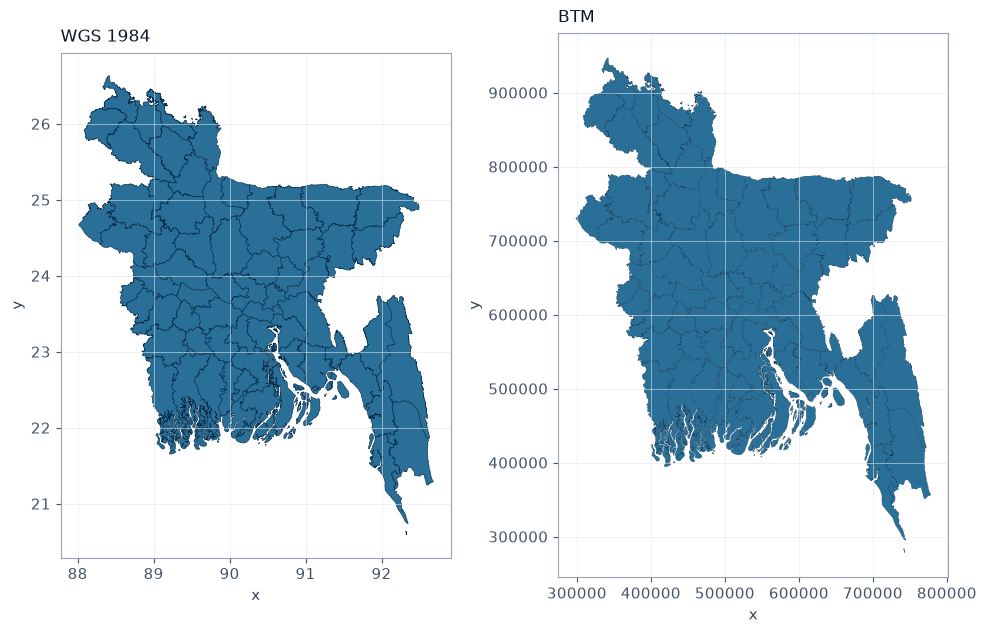

In [12]:
# Draw WGS 84 and BTM district maps side by side for a visual CRS comparison.
plot_pair(
    districts_gcs,  # left panel: geographic coordinates (degrees)
    districts_btm,  # right panel: Bangladesh Transverse Mercator (meters)
    ["WGS 1984", "BTM"],  # titles for the two map panels
    figsize=(10, 8),  # overall figure size in inches
);  # trailing semicolon suppresses a second matplotlib repr in Jupyter


`write_shapefile` stores the projected layer for later use. The `.prj` beside `bd_district_BTM.shp` records the transverse Mercator parameters.


In [13]:
# Save the BTM districts to disk and reopen to confirm feature count and CRS.
btm_path = BD_OUT / "bd_district_BTM.shp"  # output shapefile path (BTM)
# Write the reprojected districts with the BTM CRS metadata.
write_shapefile(btm_path, districts_btm, layer="bd_district", crs=btm, overwrite=True)

# Re-open the written BTM shapefile and print a short integrity check.
with read_vector_data(btm_path) as dataset:
    print(f"features: {dataset.feature_count}")  # should match the source count
    print(f"bounds:   {dataset.bounds}")  # projected extent in meters
    show_crs(dataset.crs)  # CRS read back from the BTM shapefile


features: 64
bounds:   Bounds(298487.81088878796, 278578.09791320935, 778101.7724792161, 946939.2176364288)
name:       unknown
identifier: +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs +type=crs
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m +no_defs +type=crs


## Part 3: New York

`NY_County_GCS.shp` holds the New York State county polygons. `read_vector_data` opens it the same way as the Bangladesh districts. This copy already has `NY_County_GCS.prj`.


shapefile:  NY_County_GCS.shp
.prj file:  True
driver:     ESRI Shapefile
features:   83
geometry:   Polygon
bounds:     Bounds(-79.76333193164768, 40.49908504928452, -71.855881514555, 45.011002977276995)
name:       WGS 84
identifier: EPSG:4326
geographic: True
projected:  False
EPSG:       4326
PROJ:       +proj=longlat +datum=WGS84 +no_defs +type=crs
area:       World.


,COUNTY,STATE,FIPS
0,Saint Lawrence County,NY,36089
1,Clinton County,NY,36019
2,Saint Lawrence County,NY,36089
3,Franklin County,NY,36033
4,Saint Lawrence County,NY,36089


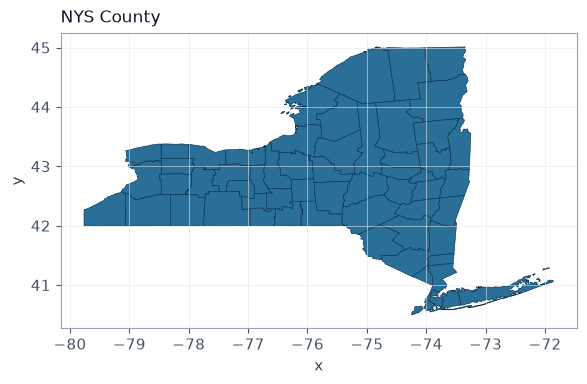

In [14]:
# Open New York counties in WGS 84, inspect metadata, preview attributes, and map.
county_path = USA / "NY_County_GCS.shp"  # NY counties already stored as GCS
print(f"shapefile:  {county_path.name}")  # basename for a short print
print(f".prj file:  {county_path.with_suffix('.prj').exists()}")  # True if .prj exists

# Open the county shapefile and collect a GeoDataFrame.
with read_vector_data(county_path) as dataset:
    print(f"driver:     {dataset.driver}")  # OGR driver name
    print(f"features:   {dataset.feature_count}")  # number of county polygons
    print(f"geometry:   {dataset.layer.geometry_type}")  # geometry type string
    print(f"bounds:     {dataset.bounds}")  # lon/lat extent of New York
    show_crs(dataset.crs)  # should report WGS 84 / EPSG:4326
    counties = dataset.to_dataframe()  # GeoDataFrame of all counties

display(counties[["COUNTY", "STATE", "FIPS"]].head())  # preview key attributes
plot_layer(counties, "NYS County", figsize=(6, 8));  # quick reference map


### Check the projection

The `.prj` is present, and the layer CRS is WGS 84 (EPSG:4326). The coordinates are still longitude and latitude in decimal degrees: x runs from about -79.76 to -71.86, and y runs from about 40.50 to 45.01. The layer is geographic, so `projected` is false. No CRS has to be assigned before reprojection.


In [15]:
# Print NY county extent and confirm the layer is still geographic (not projected).
print("total bounds (minx, miny, maxx, maxy):")  # label for the extent print
print(counties.total_bounds)  # full lon/lat extent of the counties
county_crs = define_crs(counties.crs)  # normalize the frame CRS for helpers
print(f"geographic: {is_geographic(county_crs)}")  # expect True (degrees)
print(f"projected:  {county_crs.is_projected}")  # expect False before Albers


total bounds (minx, miny, maxx, maxy):
[-79.76333193  40.49908505 -71.85588151  45.01100298]
geographic: True
projected:  False


### Reprojection

`reproject_vector` transforms the counties from WGS 1984 to **Albers Equal Area Conic NAD83**. The parameters are the North America Albers definition in `NY_County_PROJ.prj` (ESRI:102008): standard parallels at 20°N and 60°N, latitude of origin 40°N, and central meridian 96°W. The contiguous-USA parameters above (ESRI:102003) use standard parallels at 29.5°N and 45.5°N.

> +proj=aea +lat_1=20 +lat_2=60 +lat_0=40 +lon_0=-96 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs

The x and y coordinates become meters, and the layer reports `projected: True`.


In [16]:
# Define North America Albers from a PROJ string, confirm ESRI:102008 equality,
# reproject NY counties, and compare degree vs meter extents.
usa_albers = define_crs(
    # Contiguous US / North America Albers Equal Area (NAD83) PROJ string.
    "+proj=aea +lat_1=20 +lat_2=60 +lat_0=40 +lon_0=-96 "
    # Assign "+x_0.
    "+x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"
)  # close this call
# True when the PROJ string matches ESRI:102008 (North America Albers).
print("equivalent to ESRI:102008:", crs_equal(usa_albers, "ESRI:102008"))
show_crs(usa_albers)  # summarize the Albers target CRS

# Reproject county polygons from WGS 84 into Albers meters.
counties_albers = reproject_vector(counties, usa_albers)
print()  # blank line before bounds comparison
print("WGS 84 bounds (degrees):", counties.total_bounds)  # lon/lat extent
print("Albers bounds (meters): ", counties_albers.total_bounds)  # projected extent
print()  # blank line before CRS summary
show_crs(counties_albers.crs)  # CRS attached to the reprojected counties


equivalent to ESRI:102008: True
name:       unknown
identifier: ESRI:102008
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=aea +lat_0=40 +lon_0=-96 +lat_1=20 +lat_2=60 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs



WGS 84 bounds (degrees): [-79.76333193  40.49908505 -71.85588151  45.01100298]
Albers bounds (meters):  [1253128.22834201  257108.42126331 1888032.93516987  791661.99182955]

name:       North_America_Albers_Equal_Area_Conic
identifier: ESRI:102008
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=aea +lat_0=40 +lon_0=-96 +lat_1=20 +lat_2=60 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs
area:       North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. United States (USA) - Alabama; Alaska (mainland); Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; Ne

WGS 1984 and the Albers map, side by side. The left panel is in degrees. The right panel is North America Albers, in meters.


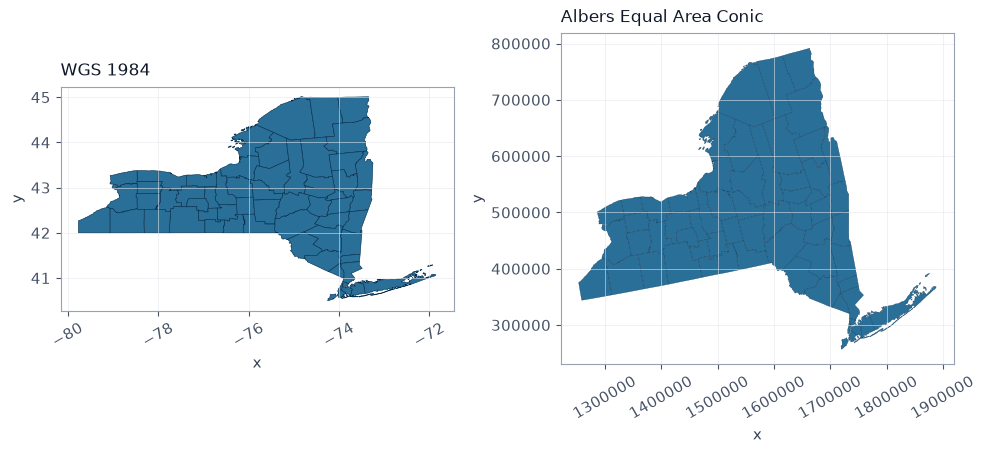

In [17]:
# Plot WGS 84 vs Albers county maps; rotate x tick labels for readability.
import matplotlib.pyplot as plt  # needed for tight_layout / show on the figure

# Build the pair of maps but keep show=False so we can tweak axes first.
fig, axes = plot_pair(
    counties,  # left: geographic lon/lat
    counties_albers,  # right: Albers Equal Area meters
    ["WGS 1984", "Albers Equal Area Conic"],  # panel titles
    figsize=(10, 8),  # overall figure size in inches
    show=False,  # return fig/axes without calling plt.show yet
)  # close this call
# Rotate x tick labels on both axes so long longitude/easting labels fit.
for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)  # 30-degree tick label rotation
fig.tight_layout()  # reduce unused whitespace around the panels
plt.show()  # display the finished figure in the notebook


`write_shapefile` writes the projected counties to `Data/00_shared/vector_data/output_folder/ny_county`. The source file `Data/00_shared/vector_data/USA/NY_County_PROJ.shp` is the same projection, already stored with the USA data.


In [18]:
# Write the Albers counties, verify the new file, and compare to the stored USA copy.
ny_path = NY_OUT / "NY_County_PROJ.shp"  # notebook output path for Albers counties
# Save counties_albers with the Albers CRS metadata.
write_shapefile(ny_path, counties_albers, layer="NY_County", crs=usa_albers, overwrite=True)

# Re-open the notebook output and print feature count, bounds, and CRS.
with read_vector_data(ny_path) as dataset:
    print(f"features: {dataset.feature_count}")  # should match the source count
    print(f"bounds:   {dataset.bounds}")  # Albers extent in meters
    show_crs(dataset.crs)  # CRS read back from the written shapefile

stored = USA / "NY_County_PROJ.shp"  # packaged reference copy under data/USA
# Open the packaged copy and print its CRS for comparison.
with read_vector_data(stored) as dataset:
    print()  # blank line before the comparison header
    print("stored USA copy")  # label for the packaged reference file
    show_crs(dataset.crs)  # CRS of the stored USA Albers copy


features: 83
bounds:   Bounds(1253128.2283420064, 257108.42126330972, 1888032.9351698712, 791661.9918295539)
name:       North_America_Albers_Equal_Area_Conic
identifier: ESRI:102008
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=aea +lat_0=40 +lon_0=-96 +lat_1=20 +lat_2=60 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs



stored USA copy


name:       Albers
identifier: ESRI:102008
geographic: False
projected:  True
EPSG:       None
PROJ:       +proj=aea +lat_0=40 +lon_0=-96 +lat_1=20 +lat_2=60 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs


## Summary

A coordinate reference system locates features on the Earth. A geographic CRS, such as WGS 84 (EPSG:4326), records longitude and latitude in degrees. A projected CRS records easting and northing in meters on a flat map. UTM does that inside 6-degree zones: Bangladesh falls in zones 45N and 46N (EPSG:32645 and EPSG:32646), and New York falls in zones 17N and 18N (EPSG:26917 and EPSG:26918). Albers Equal Area Conic is the east-west alternative used for the United States, as ESRI:102003 for the conterminous states and ESRI:102008 for North America.

`geolattice.crs` holds the shared CRS catalog. `geolattice.vector.vector_CRS` is the vector side: `define_crs` / `validate_crs` load a definition, `is_geographic` / `crs_equal` inspect it, and `reproject_vector` calculates new coordinates in a target CRS. Assigning a CRS without moving coordinates (for a layer that already uses those values) still uses GeoPandas `set_crs` after `define_crs`.

The two exercises use those steps on layers that arrive in different states.

* **Part 2.** `bd_district.shp` has no `.prj`, so the 64 district polygons open with an undefined CRS. The coordinates are degrees, about 88.01°E-92.68°E and 20.59°N-26.63°N. Assigning EPSG:4326 names that geographic CRS, and writing `bd_district_GCS.shp` stores it in a `.prj`. Projecting to the Bangladesh Transverse Mercator (`+proj=tmerc +lat_0=0 +lon_0=90 +k=0.9996 +x_0=500000 +y_0=-2000000 +datum=WGS84 +units=m`) converts those degrees to meters. The current authority name for Gulshan 303 / Bangladesh Transverse Mercator is EPSG:9678, on the Everest 1830 ellipsoid. The exercise keeps the WGS 84 form of the same projection parameters. The projected copy is `Data/00_shared/vector_data/output_folder/bangladesh/bd_district_BTM.shp`.

* **Part 3.** `NY_County_GCS.shp` already carries a WGS 84 `.prj`. The 83 counties span about -79.76° to -71.86° and 40.50° to 45.01°, and `projected` is false because the coordinates are still degrees. Reprojecting to North America Albers (ESRI:102008) puts them in meters. That definition matches `Data/00_shared/vector_data/USA/NY_County_PROJ.prj`. The new copy is `Data/00_shared/vector_data/output_folder/ny_county/NY_County_PROJ.shp`.

The side-by-side maps show the same boundaries before and after projection: degrees on the left, meters on the right. The shape of each map changes with the projection, and the coordinate numbers change units. Check the CRS before measuring distance or area, before overlaying layers, and before writing a file that other software will read. A missing `.prj` leaves the CRS undefined. A geographic CRS is the right record for longitude and latitude. A projected CRS such as UTM, the Bangladesh Transverse Mercator, or Albers is the right record when the map needs meters.


### Further reading

1. [Using map projections](https://cran.r-project.org/web/packages/oce/vignettes/D_map_projections.html)

2. [Map projections in R](https://michaelminn.net/tutorials/r-projections/index.html)

3. [Variations on map projections in R](https://www.happykhan.com/posts/map-projections-in-r/)

4. [PROJ](https://proj.org/en/stable/) and [pyproj](https://pyproj4.github.io/pyproj/stable/), which supply the definitions `geolattice.crs` and `vector_CRS` use

5. [SpatialReference.org](https://spatialreference.org/) for the WKT, PROJ, and PROJJSON forms of an authority code

6. `geolattice.vector.vector_CRS` for define / validate / reproject on vector layers, and `geolattice.raster.raster_CRS` for GDAL warp on rasters
